# Student Performance Analysis & Score Prediction

## Author
Aayaan K

## Project Type
Exploratory Data Analysis (EDA) + Machine Learning

## Tools Used
- Python
- NumPy
- Pandas
- Matplotlib
- Seaborn
- Scikit-learn

##  Problem Statement


A school wants to analyze student academic performance and identify factors associated with higher or lower scores. The goal is to understand patterns in the data and build a simple machine learning model to predict a student's math score based on other available information.

##  Import Libraries

In [15]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

## Load Dataset


In [16]:
df = pd.read_csv("../data/StudentsPerformance.csv")

##  Data Understanding


In [17]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [18]:
df.tail()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77
999,female,group D,some college,free/reduced,none,77,86,86


In [19]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [20]:
df.describe(include='all')

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
count,1000,1000,1000,1000,1000,1000.00000,1000.000000,1000.000000
unique,2,5,6,2,2,NaN,NaN,NaN
top,female,group C,some college,standard,none,NaN,NaN,NaN
freq,518,319,226,645,642,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,66.08900,69.169000,68.054000
std,NaN,NaN,NaN,NaN,NaN,15.16308,14.600192,15.195657
min,NaN,NaN,NaN,NaN,NaN,0.00000,17.000000,10.000000
25%,NaN,NaN,NaN,NaN,NaN,57.00000,59.000000,57.750000
50%,NaN,NaN,NaN,NaN,NaN,66.00000,70.000000,69.000000
75%,NaN,NaN,NaN,NaN,NaN,77.00000,79.000000,79.000000


In [21]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


In [22]:
df.shape

(1000, 8)

In [23]:
df.size

8000

In [24]:
df.columns

Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='str')

In [25]:
df.dtypes

gender                           str
race/ethnicity                   str
parental level of education      str
lunch                            str
test preparation course          str
math score                     int64
reading score                  int64
writing score                  int64
dtype: object

##  Data Cleaning


In [28]:
# Check for missing values
missing_values = df.isnull().sum()

print("Missing Values")
missing_values

Missing Values


gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

### Observation

The dataset contains no missing values. Therefore, no imputation or removal of records is required.

In [29]:
duplicates = df.duplicated().sum()

print("Duplicate Rows:", duplicates)

Duplicate Rows: 0


### Observation

No duplicate records were found in the dataset.

In [30]:
df.columns

Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='str')

In [31]:
df.columns = (
    df.columns
      .str.lower()
      .str.replace(" ", "_")
)

In [32]:
df.columns

Index(['gender', 'race/ethnicity', 'parental_level_of_education', 'lunch',
       'test_preparation_course', 'math_score', 'reading_score',
       'writing_score'],
      dtype='str')

In [33]:
categorical_columns = df.select_dtypes(include="object").columns

for col in categorical_columns:
    print(f"\n{col}")
    print(df[col].unique())


gender
<StringArray>
['female', 'male']
Length: 2, dtype: str

race/ethnicity
<StringArray>
['group B', 'group C', 'group A', 'group D', 'group E']
Length: 5, dtype: str

parental_level_of_education
<StringArray>
[ 'bachelor's degree',       'some college',    'master's degree',
 'associate's degree',        'high school',   'some high school']
Length: 6, dtype: str

lunch
<StringArray>
['standard', 'free/reduced']
Length: 2, dtype: str

test_preparation_course
<StringArray>
['none', 'completed']
Length: 2, dtype: str


C:\Users\lenovo\AppData\Local\Temp\ipykernel_6032\3674402834.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include="object").columns


## Feature Engineering


Average Score

In [34]:
df["average_score"] = (
    df["math_score"] +
    df["reading_score"] +
    df["writing_score"]
) / 3

In [35]:
df.head()

,gender,race/ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,average_score
0,female,group B,bachelor's degree,standard,none,72,72,74,72.666667
1,female,group C,some college,standard,completed,69,90,88,82.333333
2,female,group B,master's degree,standard,none,90,95,93,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,49.333333
4,male,group C,some college,standard,none,76,78,75,76.333333


Total Score

In [36]:
df["total_score"] = (
    df["math_score"] +
    df["reading_score"] +
    df["writing_score"]
)

In [37]:
df.head()

,gender,race/ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,average_score,total_score
0,female,group B,bachelor's degree,standard,none,72,72,74,72.666667,218
1,female,group C,some college,standard,completed,69,90,88,82.333333,247
2,female,group B,master's degree,standard,none,90,95,93,92.666667,278
3,male,group A,associate's degree,free/reduced,none,47,57,44,49.333333,148
4,male,group C,some college,standard,none,76,78,75,76.333333,229


Performance Grade

In [38]:
def grade(avg):
    if avg >= 90:
        return "Excellent"
    elif avg >= 75:
        return "Good"
    elif avg >= 60:
        return "Average"
    else:
        return "Poor"

In [39]:
df["performance"] = df["average_score"].apply(grade)

In [40]:
df.head()

,gender,race/ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,average_score,total_score,performance
0,female,group B,bachelor's degree,standard,none,72,72,74,72.666667,218,Average
1,female,group C,some college,standard,completed,69,90,88,82.333333,247,Good
2,female,group B,master's degree,standard,none,90,95,93,92.666667,278,Excellent
3,male,group A,associate's degree,free/reduced,none,47,57,44,49.333333,148,Poor
4,male,group C,some college,standard,none,76,78,75,76.333333,229,Good


In [42]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   gender                       1000 non-null   str    
 1   race/ethnicity               1000 non-null   str    
 2   parental_level_of_education  1000 non-null   str    
 3   lunch                        1000 non-null   str    
 4   test_preparation_course      1000 non-null   str    
 5   math_score                   1000 non-null   int64  
 6   reading_score                1000 non-null   int64  
 7   writing_score                1000 non-null   int64  
 8   average_score                1000 non-null   float64
 9   total_score                  1000 non-null   int64  
 10  performance                  1000 non-null   str    
dtypes: float64(1), int64(4), str(6)
memory usage: 86.1 KB


In [43]:
df.to_csv("../data/students_cleaned.csv", index=False)

## Summary

The following preprocessing steps were completed:

- Checked for missing values.
- Checked for duplicate records.
- Renamed columns for consistency.
- Examined categorical values.
- Verified data types.
- Created average_score.
- Created total_score.
- Created performance category.
- Saved a cleaned version of the dataset.

##  Exploratory Data Analysis


Exploratory Data Analysis (EDA) is performed to understand the distribution of variables, identify trends, detect outliers, and discover relationships between different features in the dataset.

What does the dataset look like?

In [44]:
df.head()

,gender,race/ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,average_score,total_score,performance
0,female,group B,bachelor's degree,standard,none,72,72,74,72.666667,218,Average
1,female,group C,some college,standard,completed,69,90,88,82.333333,247,Good
2,female,group B,master's degree,standard,none,90,95,93,92.666667,278,Excellent
3,male,group A,associate's degree,free/reduced,none,47,57,44,49.333333,148,Poor
4,male,group C,some college,standard,none,76,78,75,76.333333,229,Good



What is the distribution of student scores?

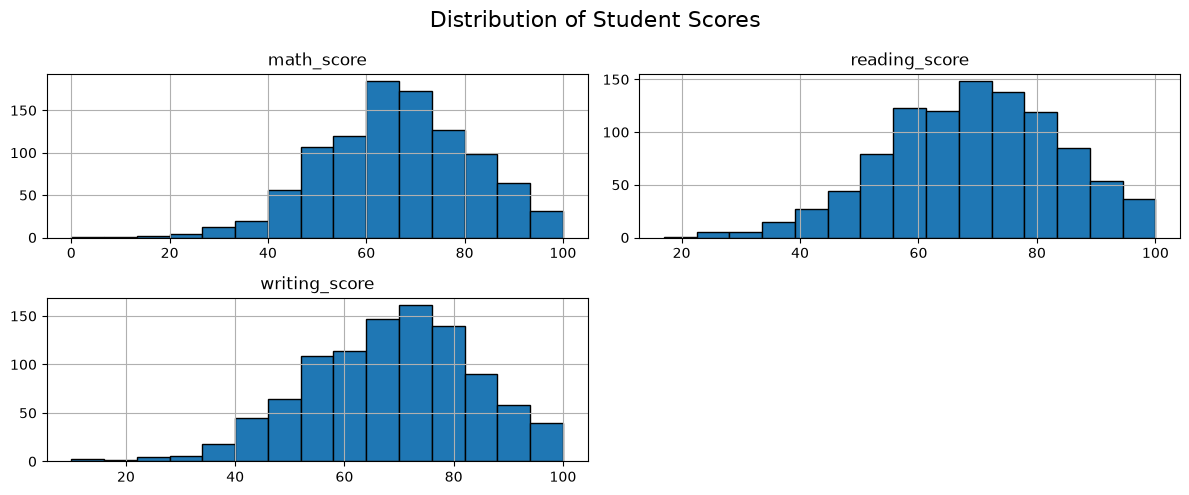

In [45]:
import matplotlib.pyplot as plt

score_columns = ["math_score", "reading_score", "writing_score"]

df[score_columns].hist(
    figsize=(12,5),
    bins=15,
    edgecolor="black"
)

plt.suptitle("Distribution of Student Scores", fontsize=16)
plt.tight_layout()
plt.show()

### Observation

- All three subjects have approximately normal distributions.
- Most students scored between 60 and 80.
- Very few students scored below 30 or above 95.

Are there any outliers?

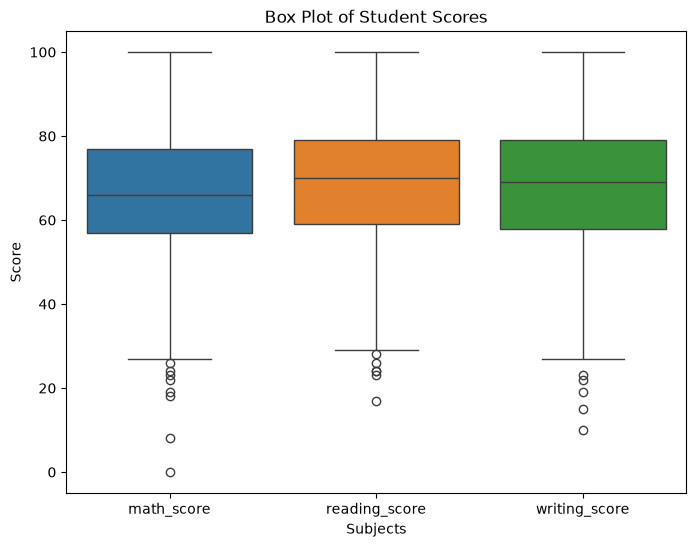

In [46]:
plt.figure(figsize=(8,6))

sns.boxplot(data=df[score_columns])

plt.title("Box Plot of Student Scores")
plt.xlabel("Subjects")
plt.ylabel("Score")

plt.show()

### Observation

- Only a few mild outliers are visible.
- Most student scores lie within a similar range.
- No extreme abnormal values were detected.

Which subject has the highest average score?

In [47]:
means = df[score_columns].mean()

means

math_score       66.089
reading_score    69.169
writing_score    68.054
dtype: float64

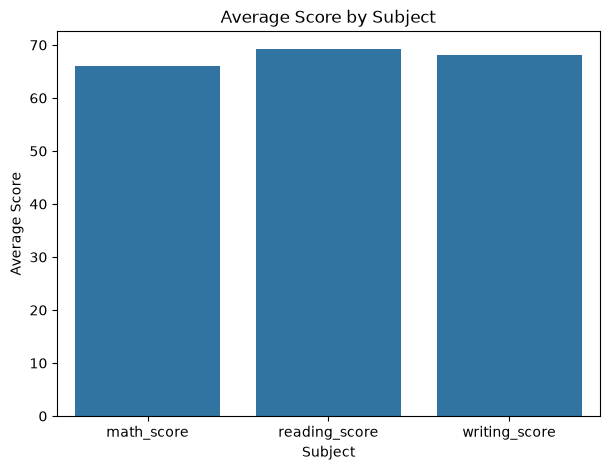

In [48]:
plt.figure(figsize=(7,5))

sns.barplot(
    x=means.index,
    y=means.values
)

plt.title("Average Score by Subject")
plt.xlabel("Subject")
plt.ylabel("Average Score")

plt.show()

### observation
reading_score has the highest average score, while the math_score is the lowest according to my observation through the nar plot

Which performance category has the most students?

In [49]:
df["performance"].value_counts()

performance
Average      391
Poor         285
Good         272
Excellent     52
Name: count, dtype: int64

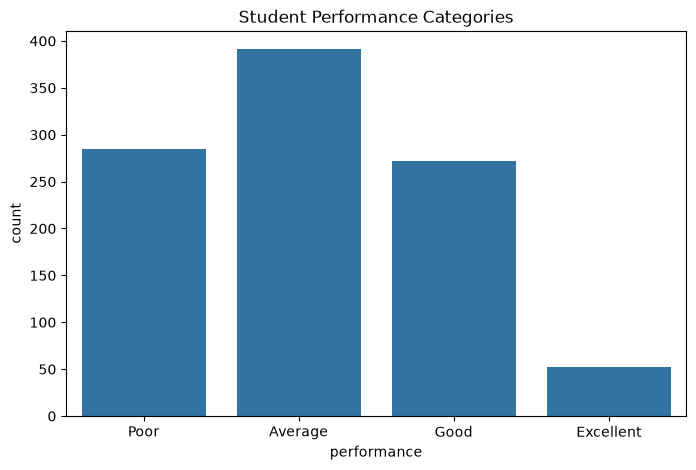

In [50]:
plt.figure(figsize=(8,5))

sns.countplot(
    x="performance",
    data=df,
    order=["Poor","Average","Good","Excellent"]
)

plt.title("Student Performance Categories")

plt.show()

### observation
average permoance is the most amount among studence where there are only a handfull of stuednts with an excellent performance and the poor performance is concerning when compared with good and excellent

Does gender affect mathematics performance?

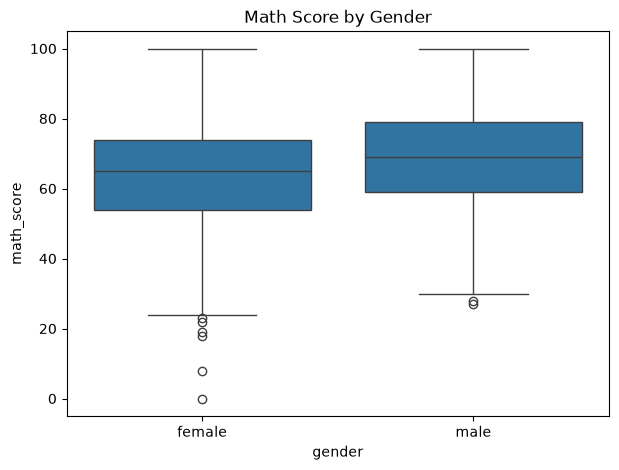

In [51]:
plt.figure(figsize=(7,5))

sns.boxplot(
    x="gender",
    y="math_score",
    data=df
)

plt.title("Math Score by Gender")

plt.show()

### observation
Gender doesn't really affect the maths score of the students although there is a diffetce when you compare the highest and the lowest marks of maths of each gender 

Does completing the test preparation course improve scores?

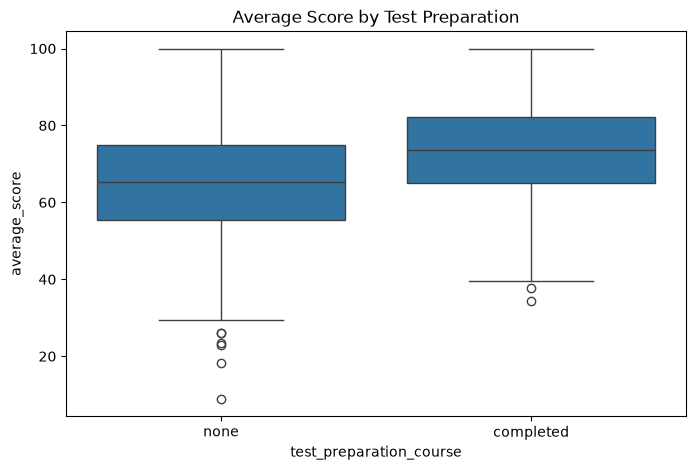

In [52]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x="test_preparation_course",
    y="average_score",
    data=df
)

plt.title("Average Score by Test Preparation")

plt.show()

Students who completed the test preparation course generally achieved higher average scores than those who did not complete it.

Does lunch type affect student performance?

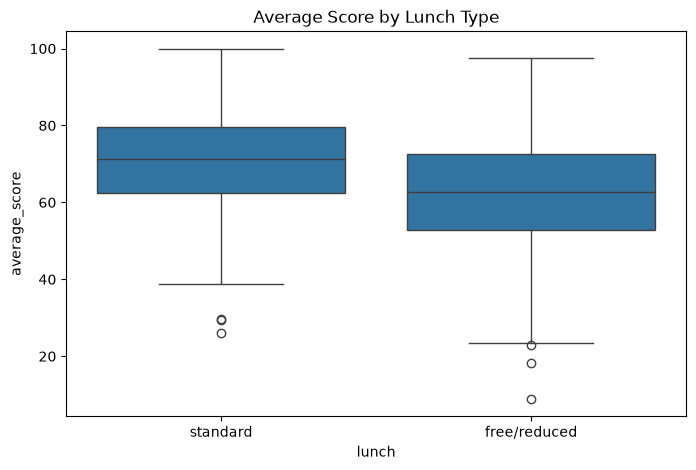

In [53]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x="lunch",
    y="average_score",
    data=df
)

plt.title("Average Score by Lunch Type")

plt.show()

### observation
yes the lunch type does affect the average score significantly as the average score is much higher of the studnets that have the standard lunch where as the free/reduced one with less privilages score less on an average 

Does parental education influence student performance?

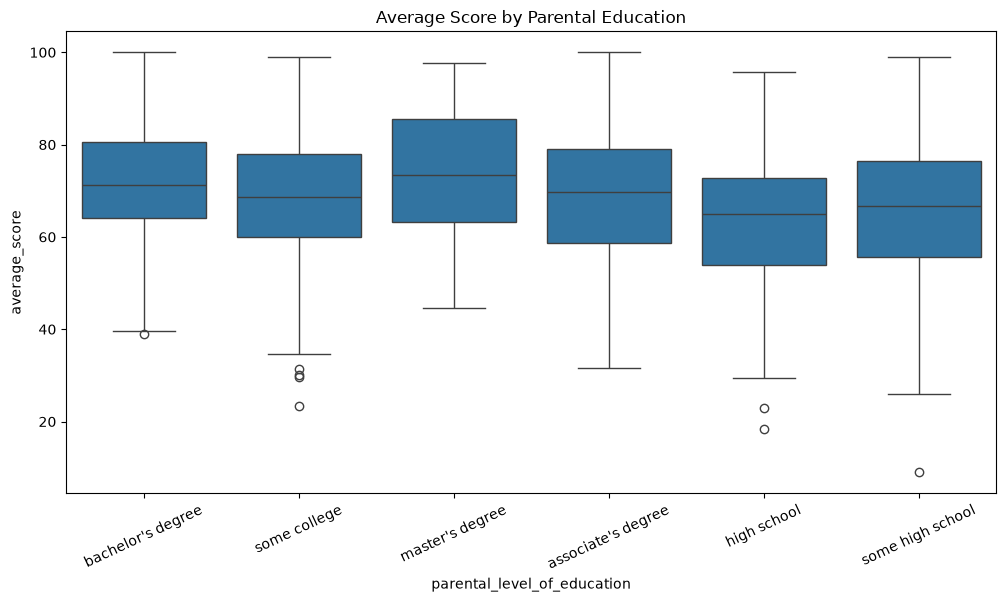

In [62]:
plt.figure(figsize=(12,6))

sns.boxplot(
    x="parental_level_of_education",
    y="average_score",
    data=df
)

plt.xticks(rotation=25)

plt.title("Average Score by Parental Education")
plt.savefig("../images/correlation_heatmap.png", dpi=300, bbox_inches="tight")

plt.show()

### observation 
The average score by parental enducation isn't half bad although there is some room for imporovement we can still see that the none of them has less then 40 of average score, but as we can see it is great for some doesnt mean it was great for all we can also see some that didnt had the same luck with parental_level of education and are facing some bad average score.

Which variables are correlated?

In [55]:
correlation = df[
    [
        "math_score",
        "reading_score",
        "writing_score",
        "average_score",
        "total_score"
    ]
].corr()

correlation

,math_score,reading_score,writing_score,average_score,total_score
math_score,1.000000,0.817580,0.802642,0.918746,0.918746
reading_score,0.817580,1.000000,0.954598,0.970331,0.970331
writing_score,0.802642,0.954598,1.000000,0.965667,0.965667
average_score,0.918746,0.970331,0.965667,1.000000,1.000000
total_score,0.918746,0.970331,0.965667,1.000000,1.000000


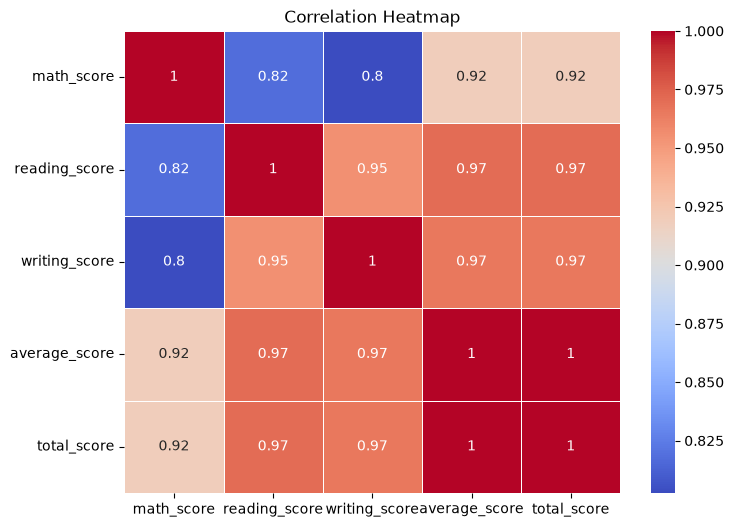

In [61]:
plt.figure(figsize=(8,6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.savefig("../images/correlation_heatmap.png", dpi=300, bbox_inches="tight")

plt.show()

### Observation

- Reading and Writing scores have a very strong positive correlation.
- Average score and Total score are almost perfectly correlated.
- Mathematics also shows a strong positive relationship with Reading and Writing.

Pair Plot

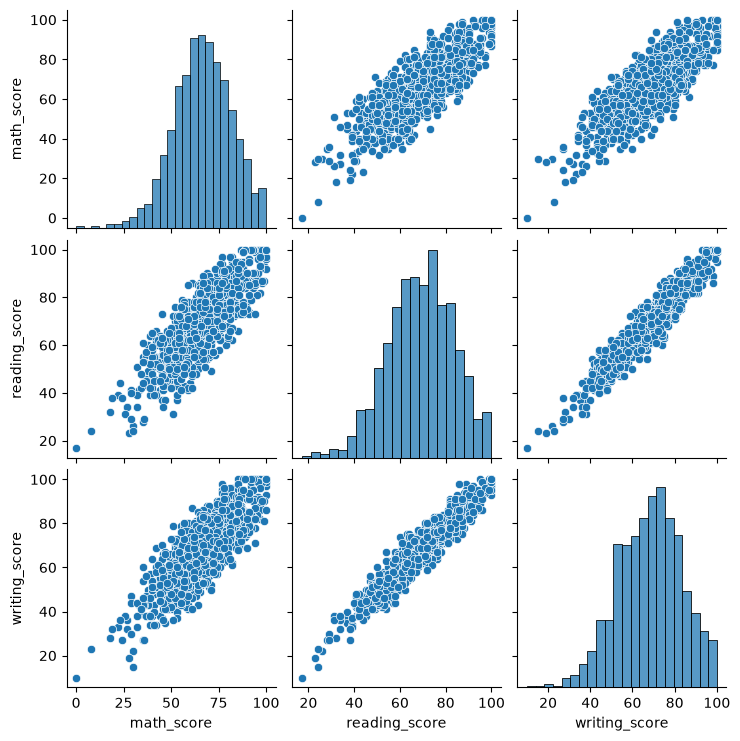

In [60]:
sns.pairplot(
    df[
        [
            "math_score",
            "reading_score",
            "writing_score"
        ]
    ]
)
plt.savefig("../images/correlation_heatmap.png", dpi=300, bbox_inches="tight")

plt.show()

Which students performed the best?

In [58]:
df.sort_values(
    by="average_score",
    ascending=False
).head(10)

,gender,race/ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,average_score,total_score,performance
916,male,group E,bachelor's degree,standard,completed,100,100,100,100.000000,300,Excellent
962,female,group E,associate's degree,standard,none,100,100,100,100.000000,300,Excellent
458,female,group E,bachelor's degree,standard,none,100,100,100,100.000000,300,Excellent
114,female,group E,bachelor's degree,standard,completed,99,100,100,99.666667,299,Excellent
712,female,group D,some college,standard,none,98,100,99,99.000000,297,Excellent
179,female,group D,some high school,standard,completed,97,100,100,99.000000,297,Excellent
165,female,group C,bachelor's degree,standard,completed,96,100,100,98.666667,296,Excellent
625,male,group D,some college,standard,completed,100,97,99,98.666667,296,Excellent
685,female,group E,master's degree,standard,completed,94,99,100,97.666667,293,Excellent
903,female,group D,bachelor's degree,free/reduced,completed,93,100,100,97.666667,293,Excellent


## summary
#  Key Insights

1. Reading scores have the highest average among all three subjects.
2. Mathematics scores show greater variability than Reading and Writing.
3. Reading and Writing scores are highly positively correlated.
4. Students who completed the test preparation course generally achieved higher scores.
5. Students receiving standard lunch tend to perform better than those receiving free/reduced lunch.
6. Most students fall into the Good performance category.
7. Very few extreme outliers are present in the dataset.
8. Higher parental education levels are generally associated with better student performance.
9. Average score and Total score are almost perfectly correlated because one is derived from the other.
10. The dataset is clean and well-suited for predictive machine learning.

##  Machine Learning


In this section, we build a Linear Regression model to predict students' mathematics scores based on demographic information and examination performance.

The machine learning workflow includes:

- Feature Selection
- Data Preprocessing
- Train-Test Split
- Model Training
- Prediction
- Model Evaluation

In [63]:
# Features
X = df.drop(
    columns=[
        "math_score",
        "average_score",
        "total_score",
        "performance"
    ]
)

# Target
y = df["math_score"]

print(X.head())

print(y.head())

   gender race/ethnicity parental_level_of_education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test_preparation_course  reading_score  writing_score  
0                    none             72             74  
1               completed             90             88  
2                    none             95             93  
3                    none             57             44  
4                    none             78             75  
0    72
1    69
2    90
3    47
4    76
Name: math_score, dtype: int64


We must not use information that already includes the target. Otherwise, the model "cheats" and your evaluation won't be realistic.

In [64]:
X = pd.get_dummies(
    X,
    drop_first=True
)

X.head()

,reading_score,writing_score,gender_male,race/ethnicity_group B,race/ethnicity_group C,race/ethnicity_group D,race/ethnicity_group E,parental_level_of_education_bachelor's degree,parental_level_of_education_high school,parental_level_of_education_master's degree,parental_level_of_education_some college,parental_level_of_education_some high school,lunch_standard,test_preparation_course_none
0,72,74,False,True,False,False,False,True,False,False,False,False,True,True
1,90,88,False,False,True,False,False,False,False,False,True,False,True,False
2,95,93,False,True,False,False,False,False,False,True,False,False,True,True
3,57,44,True,False,False,False,False,False,False,False,False,False,False,True
4,78,75,True,False,True,False,False,False,False,False,True,False,True,True


In [65]:
print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (1000, 14)
y Shape: (1000,)


In [66]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [69]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(800, 14)
(200, 14)
(800,)
(200,)


In [70]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

In [72]:
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](14,)","[ 0.24, 0.72,13.06,..., 0.76, 3.51, 3.29]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](14,)","['reading_score','writing_score','gender_male',..., 'parental_level_of_education_some high school','lunch_standard', 'test_preparation_course_none']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-10.91
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,14
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(14)


In [73]:
y_pred = model.predict(X_test)

In [74]:
predictions = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

predictions.head(10)

,Actual,Predicted
521,91,76.387970
737,53,58.885970
740,80,76.990265
660,74,76.851804
411,84,87.627378
678,81,79.014024
626,69,64.654609
513,54,53.007919
859,87,74.184710
136,51,49.213538


##  Model Evaluation


In [75]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

In [76]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", round(mae,2))
print("Mean Squared Error:", round(mse,2))
print("Root Mean Squared Error:", round(rmse,2))
print("R² Score:", round(r2,2))

Mean Absolute Error: 4.21
Mean Squared Error: 29.1
Root Mean Squared Error: 5.39
R² Score: 0.88


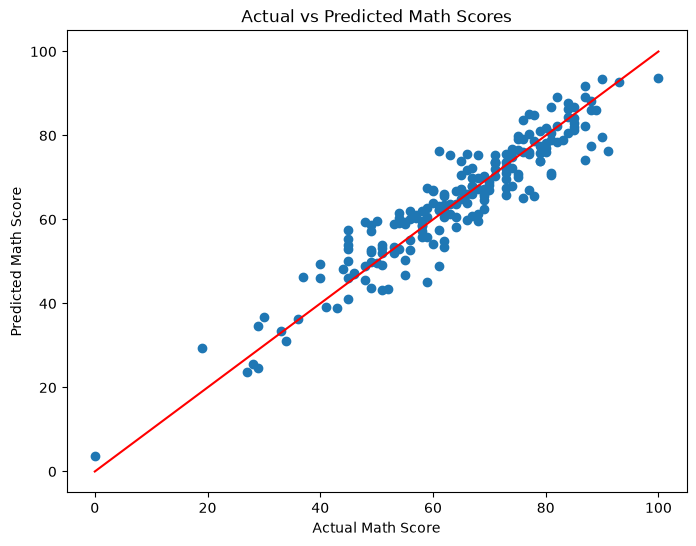

In [77]:
plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Math Score")
plt.ylabel("Predicted Math Score")

plt.title("Actual vs Predicted Math Scores")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red"
)

plt.show()

In [78]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

coefficients.sort_values(
    by="Coefficient",
    ascending=False
)

,Feature,Coefficient
2,gender_male,13.064884
6,race/ethnicity_group E,4.892649
12,lunch_standard,3.510075
13,test_preparation_course_none,3.289642
10,parental_level_of_education_some college,0.998856
8,parental_level_of_education_high school,0.929312
11,parental_level_of_education_some high school,0.756470
1,writing_score,0.724148
3,race/ethnicity_group B,0.359323
0,reading_score,0.236023


In [79]:
new_student = pd.DataFrame({
    "reading_score": [80],
    "writing_score": [82],
    "gender_male": [1],
    "race/ethnicity_group B": [0],
    "race/ethnicity_group C": [1],
    "race/ethnicity_group D": [0],
    "race/ethnicity_group E": [0],
    "parental_level_of_education_bachelor's degree": [0],
    "parental_level_of_education_high school": [1],
    "parental_level_of_education_master's degree": [0],
    "parental_level_of_education_some college": [0],
    "parental_level_of_education_some high school": [0],
    "lunch_standard": [1],
    "test_preparation_course_none": [0]
})

prediction = model.predict(new_student)

print("Predicted Math Score:", round(prediction[0],2))

Predicted Math Score: 84.23


## Machine Learning Summary

A Linear Regression model was trained to predict mathematics scores.

### Workflow

- Selected input features
- Applied one-hot encoding to categorical variables
- Performed an 80/20 train-test split
- Trained a Linear Regression model
- Generated predictions
- Evaluated model performance using MAE, MSE, RMSE, and R²
- Analyzed feature coefficients

The model demonstrates how demographic factors and performance in other subjects can be used to estimate mathematics scores.

# Conclusion

This project successfully analyzed student academic performance using Exploratory Data Analysis and Machine Learning.

The data was cleaned, explored, and visualized to understand score distributions, detect outliers, and identify relationships between variables.

Feature engineering was performed by creating additional variables such as Average Score, Total Score, and Performance Category.

Finally, a Linear Regression model was trained to predict mathematics scores based on demographic information and examination performance. The model was evaluated using standard regression metrics and demonstrated the practical application of machine learning in educational data analysis.

This project demonstrates an end-to-end data analytics workflow, including data preprocessing, visualization, statistical analysis, model building, and evaluation.